# Used-Car Price Prediction
### An end-to-end machine learning project

**Project type:** Supervised learning · Regression  
**Objective:** Predict an advertised vehicle price from vehicle characteristics.  
**Dataset:** `adverts.csv` — 402,005 vehicle listings and 12 source columns.

---

## Project overview

This project demonstrates a complete, reproducible machine-learning workflow: understanding a raw dataset, auditing data quality, exploring patterns, engineering useful features, preventing leakage, comparing models, tuning a candidate, and evaluating predictions on unseen data.

The target is `price`. Candidate predictors include mileage, registration-derived vehicle age, make, model, condition, body type, fuel type, colour, and listing date features.

### Questions

- How are vehicle prices distributed, and which groups show noticeable price differences?
- How much better do learned models perform than a simple median-price baseline?
- Which model gives the strongest holdout performance under MAE, RMSE, and R²?
- Which features appear important to the selected tree-based model?

### Success criteria

A useful model should beat the baseline on held-out data, report more than one error metric, and document limitations. A low error on this historical dataset does **not** guarantee accurate prices in today's market.

> **Reproducibility note:** Keep `adverts.csv` in the same folder as this notebook. EDA uses the full dataset; modelling uses a seeded sample by default so the workflow is practical on a typical laptop. The sample size can be changed in the configuration section.

## 1. Workflow and skills demonstrated

1. **Inspect and validate** the raw data, types, missing values, duplicates, and implausible values.
2. **Explore** the target distribution and relationships between price and selected predictors.
3. **Clean and engineer** features with documented rules.
4. **Split** train and test data before learning preprocessing parameters.
5. **Build pipelines** for imputation, scaling, categorical encoding, and modelling.
6. **Compare and tune** regression models using a holdout set and cross-validation.
7. **Evaluate and interpret** the final model, then discuss limitations and next steps.

## 2. Imports and configuration

The notebook uses common Python data-science tools and scikit-learn pipelines. Fixed random seeds help make results reproducible.

In [ ]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

SEED = 42
DATA_PATH = Path("adverts.csv")
SAMPLE_SIZE = 30_000  # Set to None to model on all cleaned rows.

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

print(f"pandas: {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")

pandas: 2.2.3
scikit-learn: 1.8.0


## 3. Load the dataset

The original file contains an identifier (`public_reference`) and a registration code (`reg_code`) as well as vehicle features. We will inspect the source columns first and decide explicitly which derived information is worth retaining.

In [ ]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. Place adverts.csv next to this notebook "
        "or update DATA_PATH to the CSV location."
    )

df_raw = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")
display(df_raw.head())

Rows: 402,005 | Columns: 12


,public_reference,mileage,reg_code,standard_colour,standard_make,standard_model,vehicle_condition,year_of_registration,price,body_type,crossover_car_and_van,fuel_type
0,202006039777689,0.0,NaN,Grey,Volvo,XC90,NEW,NaN,73970,SUV,False,Petrol Plug-in Hybrid
1,202007020778260,108230.0,61,Blue,Jaguar,XF,USED,2011.0,7000,Saloon,False,Diesel
2,202007020778474,7800.0,17,Grey,SKODA,Yeti,USED,2017.0,14000,SUV,False,Petrol
3,202007080986776,45000.0,16,Brown,Vauxhall,Mokka,USED,2016.0,7995,Hatchback,False,Diesel
4,202007161321269,64000.0,64,Grey,Land Rover,Range Rover Sport,USED,2015.0,26995,SUV,False,Diesel


In [ ]:
df_raw.info()
display(df_raw.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 402005 entries, 0 to 402004
Data columns (total 12 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   public_reference       402005 non-null  int64  
 1   mileage                401878 non-null  float64
 2   reg_code               370148 non-null  object 
 3   standard_colour        396627 non-null  object 
 4   standard_make          402005 non-null  object 
 5   standard_model         402005 non-null  object 
 6   vehicle_condition      402005 non-null  object 
 7   year_of_registration   368694 non-null  float64
 8   price                  402005 non-null  int64  
 9   body_type              401168 non-null  object 
 10  crossover_car_and_van  402005 non-null  bool   
 11  fuel_type              401404 non-null  object 
dtypes: bool(1), float64(2), int64(2), object(7)
memory usage: 34.1+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
public_reference,402005.0,NaN,NaN,NaN,202007077472444.46875,16916615997.344137,201307177852187.0,202009023197699.0,202009304400624.0,202010175124399.0,202011025683478.0
mileage,401878.0,NaN,NaN,NaN,37743.595656,34831.724018,0.0,10481.0,28629.5,56875.75,999999.0
reg_code,370148,72,17,36738,NaN,NaN,NaN,NaN,NaN,NaN,NaN
standard_colour,396627,22,Black,86287,NaN,NaN,NaN,NaN,NaN,NaN,NaN
standard_make,402005,110,BMW,37376,NaN,NaN,NaN,NaN,NaN,NaN,NaN
standard_model,402005,1168,Golf,11583,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_condition,402005,2,USED,370756,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year_of_registration,368694.0,NaN,NaN,NaN,2015.006206,7.962667,999.0,2013.0,2016.0,2018.0,2020.0
price,402005.0,NaN,NaN,NaN,17341.965799,46437.460951,120.0,7495.0,12600.0,20000.0,9999999.0
body_type,401168,16,Hatchback,167315,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data-quality audit

Before modelling, check missingness, duplicate records, numeric ranges, category cardinality, and unusual target values. This step informs the cleaning rules instead of dropping rows simply because they look unusual.

In [ ]:
missing_report = (
    df_raw.isna().sum()
    .rename("missing_count")
    .to_frame()
    .assign(missing_pct=lambda x: (100 * x["missing_count"] / len(df_raw)).round(2))
    .sort_values("missing_pct", ascending=False)
)
display(missing_report)

print(f"Exact duplicate rows: {df_raw.duplicated().sum():,}")
print(f"Non-positive prices: {(df_raw['price'] <= 0).sum():,}")
print(f"Rows with price exactly 9,999,999: {(df_raw['price'] == 9_999_999).sum():,}")
print(f"Unique makes: {df_raw['standard_make'].nunique():,}")
print(f"Unique models: {df_raw['standard_model'].nunique():,}")

,missing_count,missing_pct
year_of_registration,33311,8.29
reg_code,31857,7.92
standard_colour,5378,1.34
body_type,837,0.21
fuel_type,601,0.15
mileage,127,0.03
public_reference,0,0.00
standard_make,0,0.00
vehicle_condition,0,0.00
standard_model,0,0.00


Exact duplicate rows: 0
Non-positive prices: 0
Rows with price exactly 9,999,999: 6
Unique makes: 110
Unique models: 1,168


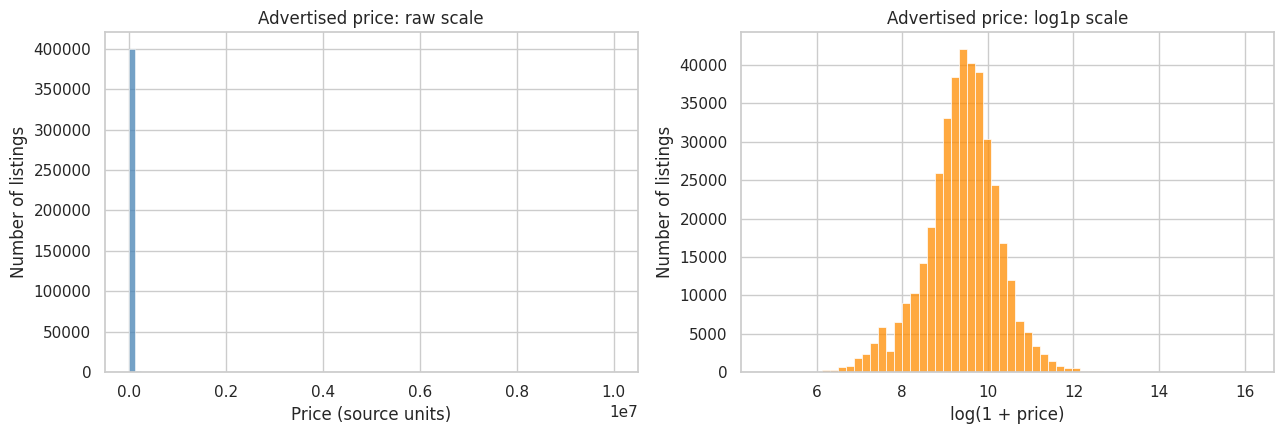

,price
count,4.020050e+05
mean,1.734197e+04
std,4.643746e+04
min,1.200000e+02
1%,1.150000e+03
5%,2.495000e+03
25%,7.495000e+03
50%,1.260000e+04
75%,2.000000e+04
90%,3.199000e+04


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df_raw["price"], bins=80, color="steelblue", ax=axes[0])
axes[0].set_title("Advertised price: raw scale")
axes[0].set_xlabel("Price (source units)")
axes[0].set_ylabel("Number of listings")

sns.histplot(np.log1p(df_raw.loc[df_raw["price"] > 0, "price"]), bins=60, color="darkorange", ax=axes[1])
axes[1].set_title("Advertised price: log1p scale")
axes[1].set_xlabel("log(1 + price)")
axes[1].set_ylabel("Number of listings")
plt.tight_layout()
plt.show()

display(df_raw["price"].describe(percentiles=[.01, .05, .25, .5, .75, .9, .95, .99]).to_frame())

### Initial observations

The raw target is likely to be strongly right-skewed, with a small number of high-priced vehicles. The plots and summary above should be used to verify the extent of this skew. The modelling section trains against `log1p(price)` to reduce the influence of extreme values, but reports MAE, RMSE, and R² after converting predictions back to the original price scale.

**Important data-specific decision:** a price of exactly `9,999,999` appears to be a placeholder/sentinel rather than a typical listing price. The cleaning step excludes only that exact value, rather than removing all expensive vehicles; rare high-value cars may be legitimate.

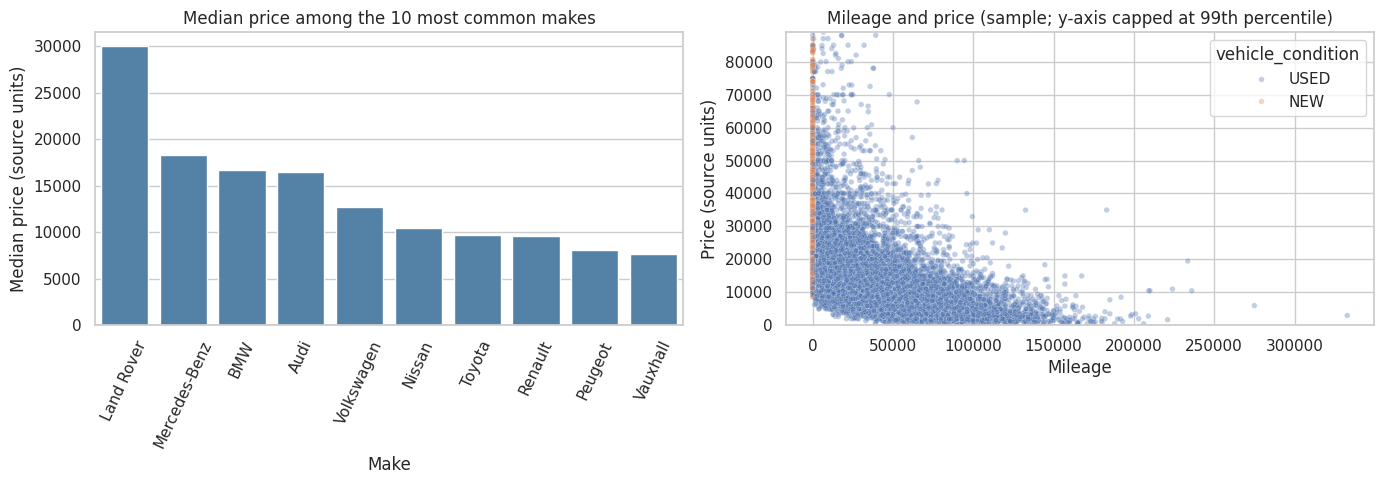

In [ ]:
# Compare median prices across a few useful groups.
top_makes = df_raw["standard_make"].value_counts().head(10).index
make_prices = (
    df_raw[df_raw["standard_make"].isin(top_makes)]
    .groupby("standard_make", as_index=False)["price"]
    .median()
    .sort_values("price", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=make_prices, x="standard_make", y="price", color="steelblue", ax=axes[0])
axes[0].set_title("Median price among the 10 most common makes")
axes[0].set_xlabel("Make")
axes[0].set_ylabel("Median price (source units)")
axes[0].tick_params(axis="x", rotation=65)

sample_for_plot = df_raw.sample(n=min(15_000, len(df_raw)), random_state=SEED)
sns.scatterplot(data=sample_for_plot, x="mileage", y="price", hue="vehicle_condition", palette="deep", alpha=0.35, s=16, ax=axes[1])
axes[1].set_ylim(0, df_raw["price"].quantile(0.99))
axes[1].set_title("Mileage and price (sample; y-axis capped at 99th percentile)")
axes[1].set_xlabel("Mileage")
axes[1].set_ylabel("Price (source units)")
plt.tight_layout()
plt.show()

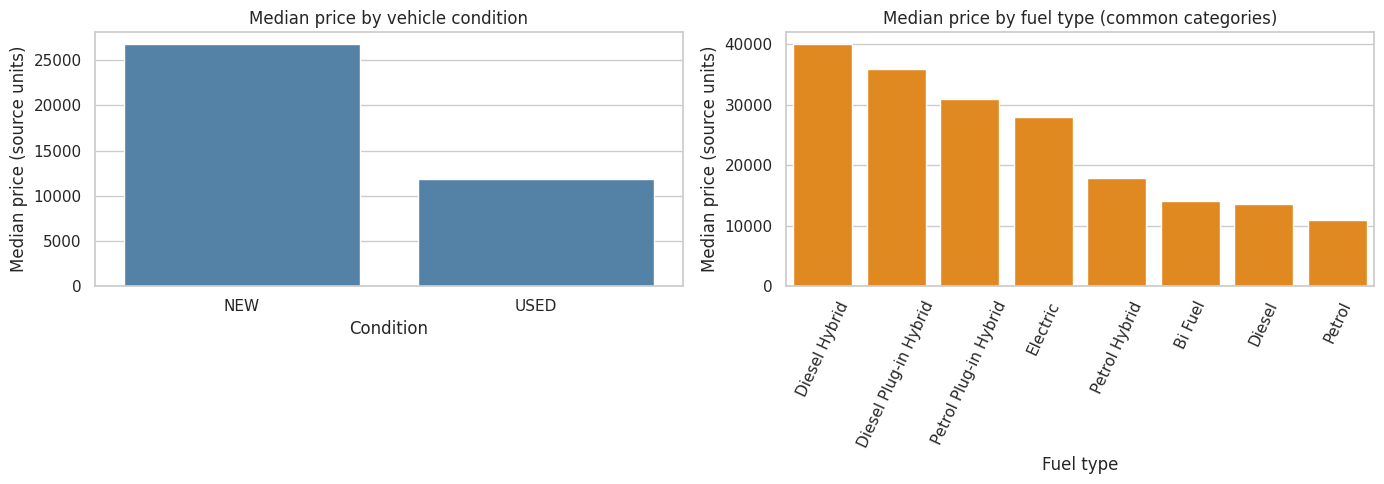

,count,median
vehicle_condition,,
NEW,31249,26760.0
USED,370756,11890.0


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
condition_summary = (
    df_raw.groupby("vehicle_condition", dropna=False)["price"]
    .agg(["count", "median"])
    .sort_values("median", ascending=False)
)
sns.barplot(data=condition_summary.reset_index(), x="vehicle_condition", y="median", color="steelblue", ax=axes[0])
axes[0].set_title("Median price by vehicle condition")
axes[0].set_xlabel("Condition")
axes[0].set_ylabel("Median price (source units)")

fuel_order = df_raw["fuel_type"].value_counts().head(8).index
fuel_medians = (df_raw[df_raw["fuel_type"].isin(fuel_order)]
                .groupby("fuel_type")["price"].median().sort_values(ascending=False))
sns.barplot(x=fuel_medians.index, y=fuel_medians.values, color="darkorange", ax=axes[1])
axes[1].set_title("Median price by fuel type (common categories)")
axes[1].set_xlabel("Fuel type")
axes[1].set_ylabel("Median price (source units)")
axes[1].tick_params(axis="x", rotation=65)
plt.tight_layout()
plt.show()

display(condition_summary)

### EDA interpretation prompts

When reviewing the plots, note whether (1) price is skewed, (2) mileage tends to be associated with price, and (3) the distributions differ by condition, make, or fuel type. These are descriptive associations, not causal effects. Do not interpret group medians as the isolated effect of a feature because vehicle make, age, mileage, and condition are related.

## 5. Cleaning and feature engineering

### Rules used

- Parse the date-like prefix of `public_reference` as the listing date, then discard the identifier itself. The raw ID is not supplied to the model.
- Derive `listing_year`, `listing_month`, and `vehicle_age = listing_year - year_of_registration`.
- Set age to zero for listings explicitly marked `NEW` when registration year is missing.
- Treat negative ages and ages above 80 years as invalid/mismatched registration data and set them to missing. This is an explicit assumption; inspect vintage-vehicle listings before using the model operationally.
- Exclude non-positive prices and the exact `9,999,999` sentinel discussed above.
- Keep missing predictor values for the pipeline to impute. Do not use the target price to construct features.
- Drop `reg_code` and the raw registration year after feature construction; retain make and model as separate categorical features.

These decisions avoid the original workflow's arbitrary frequency-based row filters and train/test preprocessing leakage.

In [ ]:
def prepare_vehicle_data(raw: pd.DataFrame) -> pd.DataFrame:
    """Clean source fields and construct model features without using the target."""
    data = raw.copy()

    # Parse the YYYYMMDD prefix in public_reference as a listing date.
    reference_text = data["public_reference"].astype("string").str[:8]
    listing_date = pd.to_datetime(reference_text, format="%Y%m%d", errors="coerce")
    data["listing_year"] = listing_date.dt.year
    data["listing_month"] = listing_date.dt.month

    registration_year = pd.to_numeric(data["year_of_registration"], errors="coerce")
    data["vehicle_age"] = data["listing_year"] - registration_year

    invalid_age = (data["vehicle_age"] < 0) | (data["vehicle_age"] > 80)
    data.loc[invalid_age, "vehicle_age"] = np.nan
    data.loc[data["vehicle_condition"].eq("NEW"), "vehicle_age"] = 0

    # Keep the target out of feature engineering; remove clearly invalid targets.
    data["price"] = pd.to_numeric(data["price"], errors="coerce")
    valid_target = data["price"].gt(0) & data["price"].ne(9_999_999)
    data = data.loc[valid_target].copy()

    # The public reference is used only to derive date features; the registration code
    # and source registration year are not passed to the model.
    drop_cols = ["public_reference", "reg_code", "year_of_registration"]
    data = data.drop(columns=drop_cols, errors="ignore")

    # Treat the boolean crossover field as numeric 0/1.
    data["crossover_car_and_van"] = data["crossover_car_and_van"].astype("float")
    return data


df_model = prepare_vehicle_data(df_raw)
feature_columns = [
    "mileage", "vehicle_age", "listing_year", "listing_month", "crossover_car_and_van",
    "standard_colour", "standard_make", "standard_model", "vehicle_condition", "body_type", "fuel_type"
]
target_column = "price"

print(f"Raw rows: {len(df_raw):,}")
print(f"Rows after target validation: {len(df_model):,}")
print(f"Rows excluded: {len(df_raw) - len(df_model):,}")
print(f"Invalid/missing vehicle_age after engineering: {df_model['vehicle_age'].isna().sum():,}")
display(df_model[feature_columns + [target_column]].head())

Raw rows: 402,005
Rows after target validation: 401,999
Rows excluded: 6
Invalid/missing vehicle_age after engineering: 2,388


,mileage,vehicle_age,listing_year,listing_month,crossover_car_and_van,standard_colour,standard_make,standard_model,vehicle_condition,body_type,fuel_type,price
0,0.0,0.0,2020,6,0.0,Grey,Volvo,XC90,NEW,SUV,Petrol Plug-in Hybrid,73970
1,108230.0,9.0,2020,7,0.0,Blue,Jaguar,XF,USED,Saloon,Diesel,7000
2,7800.0,3.0,2020,7,0.0,Grey,SKODA,Yeti,USED,SUV,Petrol,14000
3,45000.0,4.0,2020,7,0.0,Brown,Vauxhall,Mokka,USED,Hatchback,Diesel,7995
4,64000.0,5.0,2020,7,0.0,Grey,Land Rover,Range Rover Sport,USED,SUV,Diesel,26995


In [ ]:
# Check data after feature engineering.
post_clean_report = pd.DataFrame({
    "dtype": df_model[feature_columns + [target_column]].dtypes.astype(str),
    "missing_count": df_model[feature_columns + [target_column]].isna().sum(),
    "missing_pct": (100 * df_model[feature_columns + [target_column]].isna().mean()).round(2)
})
display(post_clean_report)
print("Target summary after cleaning:")
display(df_model[target_column].describe(percentiles=[.5, .9, .95, .99]).to_frame())

,dtype,missing_count,missing_pct
mileage,float64,127,0.03
vehicle_age,float64,2388,0.59
listing_year,int32,0,0.00
listing_month,int32,0,0.00
crossover_car_and_van,float64,0,0.00
standard_colour,object,5378,1.34
standard_make,object,0,0.00
standard_model,object,0,0.00
vehicle_condition,object,0,0.00
body_type,object,837,0.21


Target summary after cleaning:


,price
count,4.019990e+05
mean,1.719297e+04
std,2.586650e+04
min,1.200000e+02
50%,1.260000e+04
90%,3.199000e+04
95%,4.381520e+04
99%,8.875864e+04
max,3.799995e+06


## 6. Prepare training and test data

The holdout test set is kept separate until final evaluation. To keep runtime manageable, a seeded sample is used for modelling; the exploratory analysis above still uses the complete source file. Because the records largely describe historical adverts, a random split measures performance on similar-period listings and is not a substitute for validation on newer market data.

In [ ]:
if SAMPLE_SIZE is not None and len(df_model) > SAMPLE_SIZE:
    df_work = df_model.sample(n=SAMPLE_SIZE, random_state=SEED).copy()
else:
    df_work = df_model.copy()

X = df_work[feature_columns].copy()
y = df_work[target_column].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

print(f"Modelling rows: {len(df_work):,}")
print(f"Training rows:  {len(X_train):,}")
print(f"Test rows:     {len(X_test):,}")
print(f"Feature count before encoding: {X_train.shape[1]}")

Modelling rows: 30,000
Training rows:  24,000
Test rows:     6,000
Feature count before encoding: 11


## 7. Preprocessing pipeline

All preprocessing is fitted **inside** each model pipeline. That means medians, category vocabularies, and scaling parameters are learned from the training fold only, then applied consistently to validation/test data. One-hot encoding safely handles previously unseen categories. Infrequent categories are grouped to limit the number of encoded features, especially for vehicle models.

In [ ]:
numeric_features = [
    "mileage", "vehicle_age", "listing_year", "listing_month", "crossover_car_and_van"
]
categorical_features = [
    "standard_colour", "standard_make", "standard_model", "vehicle_condition", "body_type", "fuel_type"
]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    # with_mean=False is compatible with sparse matrices produced by one-hot encoding.
    ("scaler", StandardScaler(with_mean=False))
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=50))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['mileage', 'vehicle_age', 'listing_year', 'listing_month', 'crossover_car_and_van']
Categorical features: ['standard_colour', 'standard_make', 'standard_model', 'vehicle_condition', 'body_type', 'fuel_type']


## 8. Define evaluation metrics

The target is trained on `log1p(price)` because the raw price distribution contains a long right tail. Predictions are transformed back with `expm1` before reporting the final error metrics, so MAE and RMSE remain interpretable in the source price units.

- **MAE:** average absolute prediction error; less sensitive to extreme errors than RMSE.
- **RMSE:** penalises large errors more strongly.
- **R²:** proportion of test-set variance explained relative to predicting the test-set mean (can be negative).

The `9,999,999` sentinel is excluded, but legitimate expensive cars are retained. This means RMSE can still be strongly influenced by rare luxury listings.

In [ ]:
def regression_metrics(y_true, y_pred):
    y_pred = np.maximum(0, np.asarray(y_pred))
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

def fit_log_target_pipeline(model, X_fit, y_fit):
    """Fit a pipeline to log1p(price)."""
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipeline.fit(X_fit, np.log1p(y_fit))
    return pipeline

def predict_price(fitted_pipeline, X_eval):
    """Convert log-space predictions back to non-negative price units."""
    log_pred = fitted_pipeline.predict(X_eval)
    return np.maximum(0, np.expm1(log_pred))

## 9. Compare baseline and candidate models

A simple median baseline gives a reference point: complex models should outperform it on unseen data. The candidates cover a regularised linear model and two tree-based models with different levels of flexibility.

In [ ]:
candidate_models = {
    "Median baseline": DummyRegressor(strategy="median"),
    "Ridge regression": Ridge(alpha=10.0),
    "Decision tree": DecisionTreeRegressor(
        max_depth=18, min_samples_leaf=10, random_state=SEED
    ),
    "Random forest": RandomForestRegressor(
        n_estimators=40, max_depth=18, min_samples_leaf=5,
        random_state=SEED, n_jobs=2
    )
}

fitted_models = {}
rows = []
for model_name, estimator in candidate_models.items():
    fitted = fit_log_target_pipeline(estimator, X_train, y_train)
    predictions = predict_price(fitted, X_test)
    fitted_models[model_name] = fitted
    rows.append({"Model": model_name, **regression_metrics(y_test, predictions)})

comparison_df = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
display(comparison_df.round({"MAE": 0, "RMSE": 0, "R2": 3}))

,Model,MAE,RMSE,R2
0,Random forest,3918.0,49845.0,0.094
1,Decision tree,4370.0,49919.0,0.092
2,Ridge regression,4374.0,50134.0,0.084
3,Median baseline,10368.0,52611.0,-0.009


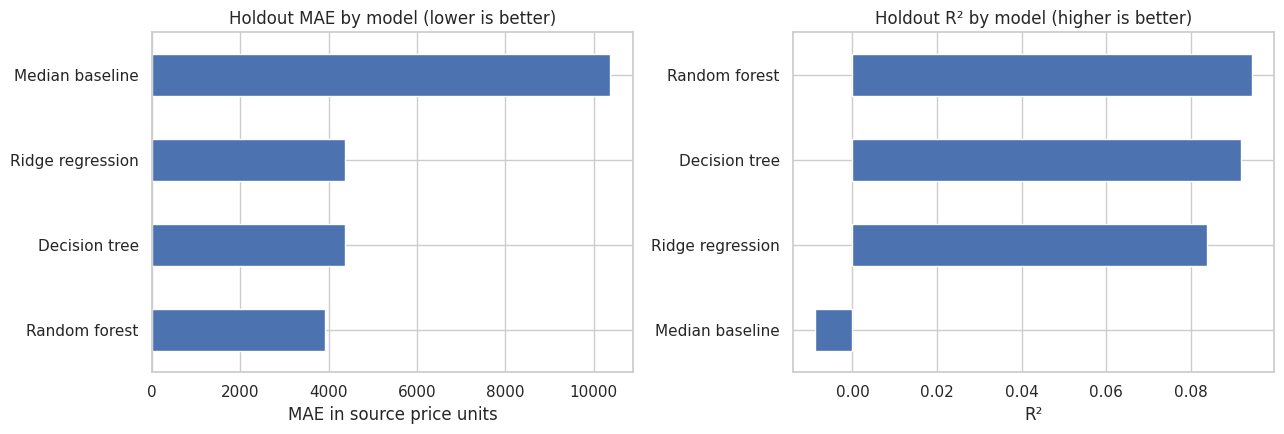

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_metrics = comparison_df.set_index("Model")
plot_metrics["MAE"].sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Holdout MAE by model (lower is better)")
axes[0].set_xlabel("MAE in source price units")
axes[0].set_ylabel("")

plot_metrics["R2"].sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Holdout R² by model (higher is better)")
axes[1].set_xlabel("R²")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

### Model selection

Use the metric table and charts above to decide whether the added complexity is worthwhile. MAE is the primary metric for a typical prediction error, while RMSE highlights large misses. Do not select a model on training performance alone. In the next section, hyperparameter tuning is carried out using training data only; the test set remains reserved for final evaluation.

## 10. Hyperparameter tuning with cross-validation

We tune the random forest using a reproducible subset of the training data to keep runtime practical. The search uses three-fold cross-validation and RMSE in log-price space. The best parameter setting is then refitted on the full training split before its holdout results are measured.

In [ ]:
# Limit the tuning search dataset for runtime; the holdout test set is not used here.
TUNING_SAMPLE_SIZE = min(12_000, len(X_train))
tune_idx = X_train.sample(n=TUNING_SAMPLE_SIZE, random_state=SEED).index
X_tune = X_train.loc[tune_idx]
y_tune_log = np.log1p(y_train.loc[tune_idx])

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=25, random_state=SEED, n_jobs=2
    ))
])

param_distributions = {
    "model__max_depth": [12, 20, 30, None],
    "model__min_samples_leaf": [2, 5, 10],
    "model__max_features": [0.7, 1.0]
}

search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=3,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=SEED,
    n_jobs=1,
    return_train_score=True,
    verbose=1
)
search.fit(X_tune, y_tune_log)

print("Best parameters:")
print(search.best_params_)
print(f"Best mean CV RMSE in log-price space: {-search.best_score_:.4f}")

Fitting 3 folds for each of 3 candidates, totalling 9 fits


Best parameters:
{'model__min_samples_leaf': 5, 'model__max_features': 1.0, 'model__max_depth': 30}
Best mean CV RMSE in log-price space: 0.3434


In [ ]:
cv_results = pd.DataFrame(search.cv_results_)
cv_summary = cv_results[[
    "rank_test_score", "mean_test_score", "std_test_score", "mean_train_score",
    "param_model__max_depth", "param_model__min_samples_leaf", "param_model__max_features"
]].sort_values("rank_test_score").rename(columns={
    "rank_test_score": "rank",
    "mean_test_score": "mean_cv_score (negative RMSE)",
    "std_test_score": "cv_score_std",
    "mean_train_score": "mean_train_score",
    "param_model__max_depth": "max_depth",
    "param_model__min_samples_leaf": "min_samples_leaf",
    "param_model__max_features": "max_features"
})
display(cv_summary)

,rank,mean_cv_score (negative RMSE),cv_score_std,mean_train_score,max_depth,min_samples_leaf,max_features
1,1,-0.343433,0.001327,-0.262238,30,5,1.0
2,2,-0.348259,0.003409,-0.266768,12,2,0.7
0,3,-0.362935,0.006339,-0.320955,20,10,0.7


## 11. Final holdout evaluation

The best search configuration is now refitted on the complete training split. This is the first time the tuning choice is used to create the final candidate; the test split is still untouched by preprocessing and model fitting.

In [ ]:
best_params = search.best_params_.copy()
# Rebuild the tuned estimator with the selected settings and fit on all training rows.
tuned_rf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=40,
        max_depth=best_params["model__max_depth"],
        min_samples_leaf=best_params["model__min_samples_leaf"],
        max_features=best_params["model__max_features"],
        random_state=SEED,
        n_jobs=2
    ))
])
tuned_rf.fit(X_train, np.log1p(y_train))
tuned_pred = predict_price(tuned_rf, X_test)
tuned_metrics = regression_metrics(y_test, tuned_pred)

final_comparison = pd.concat([
    comparison_df,
    pd.DataFrame([{"Model": "Tuned random forest", **tuned_metrics}])
], ignore_index=True).sort_values("MAE").reset_index(drop=True)

display(final_comparison.round({"MAE": 0, "RMSE": 0, "R2": 3}))
print(f"Test-set rows evaluated: {len(y_test):,}")

,Model,MAE,RMSE,R2
0,Tuned random forest,3791.0,49807.0,0.096
1,Random forest,3918.0,49845.0,0.094
2,Decision tree,4370.0,49919.0,0.092
3,Ridge regression,4374.0,50134.0,0.084
4,Median baseline,10368.0,52611.0,-0.009


Test-set rows evaluated: 6,000


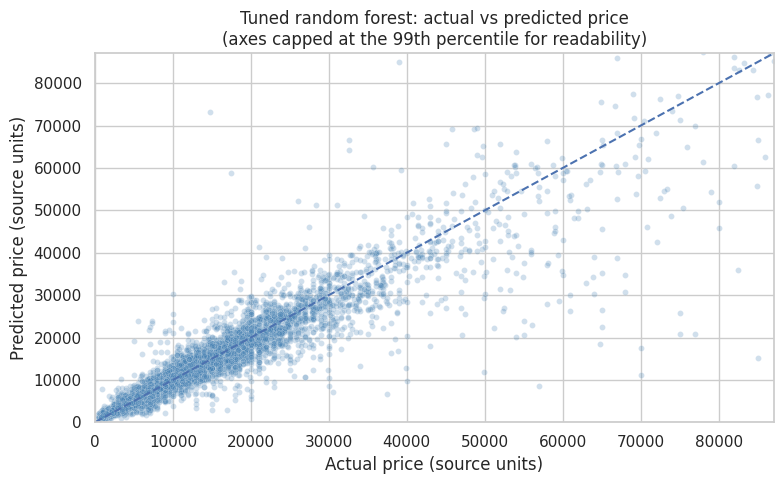

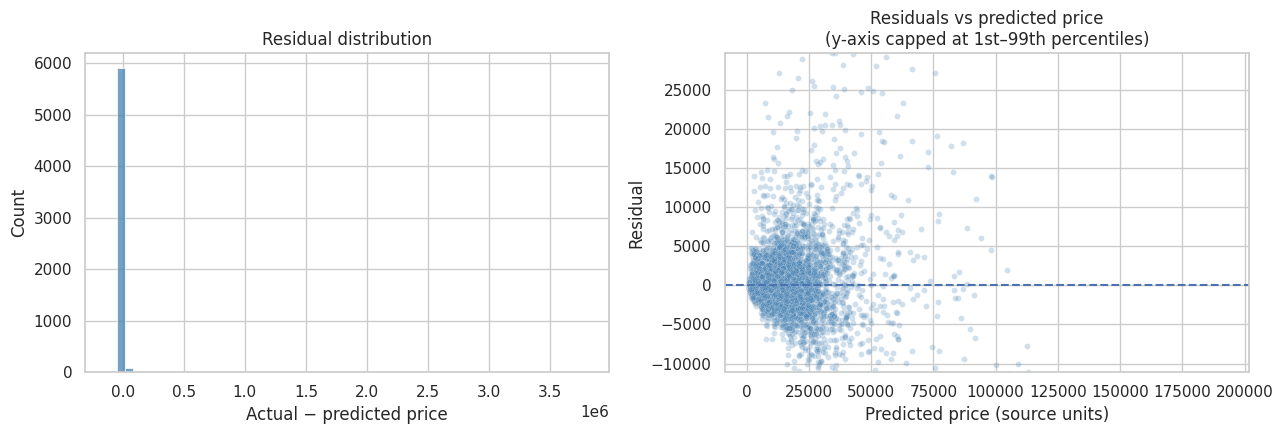

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(x=y_test, y=tuned_pred, color="steelblue", alpha=0.25, s=18, ax=ax)
upper = max(float(y_test.quantile(0.99)), float(np.quantile(tuned_pred, 0.99)))
ax.plot([0, upper], [0, upper], linestyle="--")
ax.set_xlim(0, upper)
ax.set_ylim(0, upper)
ax.set_title("Tuned random forest: actual vs predicted price\n(axes capped at the 99th percentile for readability)")
ax.set_xlabel("Actual price (source units)")
ax.set_ylabel("Predicted price (source units)")
plt.tight_layout()
plt.show()

residuals = np.asarray(y_test) - tuned_pred
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(residuals, bins=60, color="steelblue", ax=axes[0])
axes[0].set_title("Residual distribution")
axes[0].set_xlabel("Actual − predicted price")

sns.scatterplot(x=tuned_pred, y=residuals, color="steelblue", alpha=0.25, s=18, ax=axes[1])
axes[1].axhline(0, linestyle="--")
axes[1].set_ylim(np.quantile(residuals, 0.01), np.quantile(residuals, 0.99))
axes[1].set_title("Residuals vs predicted price\n(y-axis capped at 1st–99th percentiles)")
axes[1].set_xlabel("Predicted price (source units)")
axes[1].set_ylabel("Residual")
plt.tight_layout()
plt.show()

### Tail-aware evaluation: typical-price segment vs full test set

The overall RMSE and R² can be dominated by a few unusually expensive listings. To make this visible rather than silently removing valid vehicles, compare the full test set with a secondary segment whose price is at or below the **99th percentile of the training target**. This threshold is calculated from training data only. The overall metrics remain the primary reported results; the segment metrics are a diagnostic and do not change model selection.

In [ ]:
typical_price_cap = y_train.quantile(0.99)
typical_mask = y_test <= typical_price_cap
all_test_metrics = regression_metrics(y_test, tuned_pred)
typical_segment_metrics = regression_metrics(
    y_test.loc[typical_mask], np.asarray(tuned_pred)[np.asarray(typical_mask)]
)
segment_metrics = pd.DataFrame([
    {"Segment": "All test rows", "Rows": len(y_test), **all_test_metrics},
    {"Segment": f"At/below training 99th percentile ({typical_price_cap:,.0f})",
     "Rows": int(typical_mask.sum()), **typical_segment_metrics}
])
display(segment_metrics.round({"MAE": 0, "RMSE": 0, "R2": 3}))
print(f"Share of test listings at/below this threshold: {typical_mask.mean():.1%}")

,Segment,Rows,MAE,RMSE,R2
0,All test rows,6000,3791.0,49807.0,0.096
1,"At/below training 99th percentile (84,995)",5933,2647.0,5512.0,0.806


Share of test listings at/below this threshold: 98.9%


## 12. Feature importance

For the tuned random forest, impurity-based feature importance provides a quick indication of which encoded inputs were most useful for splitting the training data. This is a model-specific diagnostic, **not** a causal explanation. Importance can be distributed across correlated features and can favour features with many possible splits; permutation importance on a carefully selected validation sample is a useful follow-up.

,feature,importance
1,numeric__vehicle_age,0.550141
196,categorical__body_type_Hatchback,0.118366
0,numeric__mileage,0.076781
35,categorical__standard_make_Land Rover,0.022068
55,categorical__standard_make_infrequent_sklearn,0.019959
23,categorical__standard_make_Audi,0.018839
44,categorical__standard_make_Porsche,0.018415
24,categorical__standard_make_BMW,0.015298
190,categorical__standard_model_infrequent_sklearn,0.013134
204,categorical__fuel_type_Petrol,0.012516


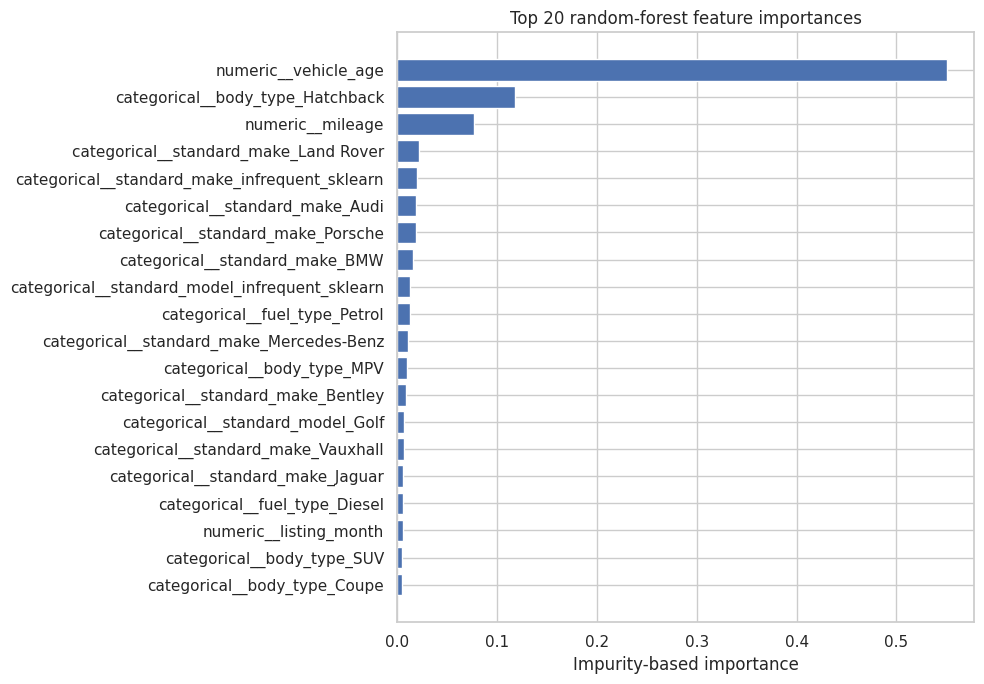

In [ ]:
fitted_preprocessor = tuned_rf.named_steps["preprocessor"]
fitted_forest = tuned_rf.named_steps["model"]
encoded_feature_names = fitted_preprocessor.get_feature_names_out()
importance_df = pd.DataFrame({
    "feature": encoded_feature_names,
    "importance": fitted_forest.feature_importances_
}).sort_values("importance", ascending=False)

display(importance_df.head(20))

plot_importance = importance_df.head(20).sort_values("importance", ascending=True)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(plot_importance["feature"], plot_importance["importance"])
ax.set_title("Top 20 random-forest feature importances")
ax.set_xlabel("Impurity-based importance")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 13. Inspect individual predictions

A few test rows help make model output concrete. These are examples, not a substitute for aggregate evaluation. Large misses should be investigated by segment (for example, rare makes, luxury vehicles, or listings with missing mileage/age).

In [ ]:
prediction_examples = X_test.copy()
prediction_examples["actual_price"] = y_test
prediction_examples["predicted_price"] = tuned_pred
prediction_examples["absolute_error"] = np.abs(prediction_examples["actual_price"] - prediction_examples["predicted_price"])

print("Typical examples (lowest absolute errors):")
display(prediction_examples.sort_values("absolute_error").head(5))
print("Largest errors in this test sample:")
display(prediction_examples.sort_values("absolute_error", ascending=False).head(10))

Typical examples (lowest absolute errors):


,mileage,vehicle_age,listing_year,listing_month,crossover_car_and_van,standard_colour,standard_make,standard_model,vehicle_condition,body_type,fuel_type,actual_price,predicted_price,absolute_error
125389,123000.0,14.0,2020,10,0.0,Black,Land Rover,Range Rover Sport,USED,SUV,Diesel,5500,5499.714764,0.285236
166943,10.0,0.0,2020,9,0.0,Multicolour,Volkswagen,Polo,NEW,Hatchback,Petrol,16900,16898.967384,1.032616
271907,0.0,0.0,2020,10,0.0,White,Dacia,Duster,NEW,SUV,Petrol,14869,14867.955291,1.044709
85766,3943.0,1.0,2019,5,0.0,White,BMW,M6,USED,Convertible,Petrol,49990,49991.098960,1.098960
21795,93460.0,6.0,2020,9,0.0,White,BMW,5 Series,USED,Saloon,Diesel,10500,10501.327272,1.327272


Largest errors in this test sample:


,mileage,vehicle_age,listing_year,listing_month,crossover_car_and_van,standard_colour,standard_make,standard_model,vehicle_condition,body_type,fuel_type,actual_price,predicted_price,absolute_error
198060,300.0,3.0,2020,8,0.0,NaN,Ferrari,LaFerrari,USED,NaN,NaN,3799995,11791.624334,3.788203e+06
113291,2630.0,3.0,2020,6,0.0,Black,Aston Martin,Vanquish,USED,Coupe,Petrol,499950,165965.809860,3.339842e+05
65634,8300.0,4.0,2020,8,0.0,Black,Lamborghini,Aventador,USED,Convertible,Petrol,279950,96039.090033,1.839109e+05
229220,1600.0,1.0,2020,3,0.0,Red,Ferrari,488 Pista,USED,Coupe,Petrol,289948,127023.293497,1.629247e+05
270716,8000.0,1.0,2020,3,0.0,Black,Mercedes-Benz,G Class,USED,SUV,Petrol,174950,54073.846906,1.208762e+05
197720,101.0,0.0,2020,8,0.0,NaN,Mercedes-Benz,V Class,USED,MPV,Diesel,160200,39794.509549,1.204055e+05
208166,11000.0,1.0,2020,10,0.0,Blue,Bentley,Bentayga,USED,SUV,Petrol,137995,20535.099850,1.174599e+05
160845,10.0,0.0,2020,9,0.0,Grey,Mercedes-Benz,AMG GT,USED,Convertible,Petrol,159975,46482.999305,1.134920e+05
98051,530.0,NaN,2016,4,0.0,Grey,Lotus,Evora,USED,Coupe,Petrol,64995,175175.337377,1.101803e+05
132050,4900.0,4.0,2020,7,0.0,NaN,Caterham,Seven,USED,Convertible,Petrol,22995,130252.682036,1.072577e+05


## 14. Results and conclusions

Use the metrics calculated in this notebook to write a concise portfolio summary. A suitable discussion should answer:

- Which model achieved the lowest test MAE, and did it outperform the median baseline?
- How did RMSE compare with MAE? A much larger RMSE can indicate a small number of very large errors.
- Did tuning improve the untuned random forest on the holdout set?
- Which features were important, and do those patterns make sense given the EDA?
- What would need to change before using this model for live pricing?

The following cell prints the best-performing model under test MAE and compares it with the baseline; use the actual output rather than assuming a particular model will win.

In [ ]:
best_row = final_comparison.sort_values("MAE").iloc[0]
baseline_row = final_comparison.loc[final_comparison["Model"].eq("Median baseline")].iloc[0]
mae_improvement = 100 * (baseline_row["MAE"] - best_row["MAE"]) / baseline_row["MAE"]

print(f"Best model by test MAE: {best_row['Model']}")
print(f"Test MAE: {best_row['MAE']:,.2f}")
print(f"Test RMSE: {best_row['RMSE']:,.2f}")
print(f"Test R²: {best_row['R2']:.3f}")
print(f"MAE reduction versus median baseline: {mae_improvement:.1f}%")

Best model by test MAE: Tuned random forest
Test MAE: 3,790.54
Test RMSE: 49,807.15
Test R²: 0.096
MAE reduction versus median baseline: 63.4%


## 15. Limitations and next steps

### Limitations

- **Historical data:** listing references indicate that most adverts date from 2020. Market prices, supply, and vehicle mix change, so these scores should not be treated as current-market accuracy.
- **Random holdout:** train and test rows come from a similar historical period. A temporal split would better test generalisation to later adverts if a sufficiently large time range were available.
- **Rare models and luxury listings:** a random sample and grouping of infrequent categories may under-represent specialist vehicles.
- **Data quality assumptions:** `9,999,999` is treated as a sentinel; registration years that produce ages below zero or above 80 are set to missing. These assumptions should be confirmed against the data source.
- **Unobserved listing factors:** trim, engine size, transmission, service history, condition details, location, seller type, and accident history may materially influence price but are not available in this dataset.
- **Feature importance is not causality:** the model's rankings describe predictive use within this dataset, not the effect of changing a feature.

### Potential improvements

1. Validate with a time-based holdout and, if possible, a newer external dataset.
2. Compare against gradient boosting methods (for example, HistGradientBoosting or a gradient-boosted tree library) and tune models under the same split strategy.
3. Evaluate MAE by vehicle condition, make, price band, and age to find weak segments.
4. Add stronger vehicle descriptors if available, and validate the registration-date assumptions with domain knowledge.
5. Use permutation importance or SHAP on a representative sample for a more informative model explanation.
6. Save the fitted preprocessing/model pipeline and document input validation before any deployment.

## Final takeaway

This project presents a reproducible baseline for vehicle-price prediction and demonstrates the main supervised-learning workflow. The most defensible conclusion is the one supported by the holdout metrics, diagnostics, and known limits of this historical dataset—not simply the model with the most complex algorithm.

---

### Appendix: original feature inventory

| Source column | Role in this notebook | Reason |
|---|---|---|
| `public_reference` | Used to derive listing year/month, then dropped | Identifier itself should not become a predictor |
| `reg_code` | Dropped | Registration code is redundant once age is engineered; missingness is substantial |
| `year_of_registration` | Used to derive `vehicle_age`, then dropped | Derived age expresses vehicle age relative to listing date |
| `price` | Target | Value to predict |
| `mileage` | Numeric predictor | Vehicle usage measure |
| `standard_make`, `standard_model` | Categorical predictors | Vehicle identity/model characteristics |
| `vehicle_condition` | Categorical predictor | NEW/USED distinction carries information not captured by mileage alone |
| `body_type`, `fuel_type`, `standard_colour` | Categorical predictors | Vehicle characteristics |
| `crossover_car_and_van` | Numeric 0/1 predictor | Binary vehicle classification |